In [1]:
#%pip install numpy
import numpy as np
#%pip install matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl

#%pip install scikit-image
import skimage
#%pip install scikit-learn
from sklearn.ensemble import RandomForestClassifier
#%pip install opencv-python
import cv2

from pathlib import Path
import sys
sys.path.append(str(Path("..").resolve()))

In [2]:
from scripts_.tilt_correction import baseplane_filter
from scripts_.plot_vk_data import plot_vk4_height, plot_vk4_reflected_light
from scripts_.load_vk_data import parse_vk6_file, parse_vk4_file
from scripts_.feature_enhancement import feature_enhancement_proceedings

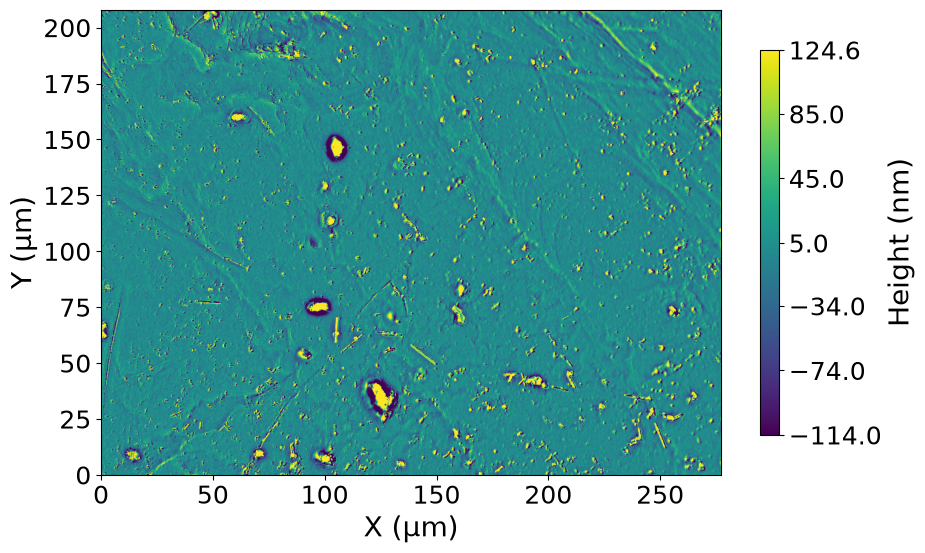

In [3]:
#file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y1_X1.vk4")
file_name = Path("../raw_data_vk/NaCl sample 3 Milan/Side 1/Stitched 50x small region/Auto mode/20260619151838_Y1_X1.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)


data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, 60)
data_1_vk4_enhanced = feature_enhancement_proceedings(data_1_vk4_tiltcorr)


ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')
#plt.savefig('image4.png')

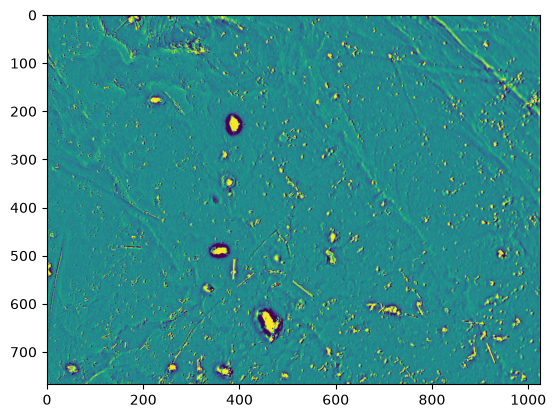

In [4]:
image = data_1_vk4_enhanced['feature_enhanced']  #cv2.imread('./notebooks/Test image.jpeg', cv2.IMREAD_COLOR_RGB)

plt.imshow(image)
plt.savefig('Test image 3.png', transparent=True)
plt.savefig('image4.png')
plt.show()

In [5]:
#image4 = cv2.imread(Path("../notebooks/Screenshot 2026-07-07 115236.png"), cv2.IMREAD_COLOR_RGB)
##image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
#
#plt.imshow(image4)
##plt.axis("off")
#plt.show()

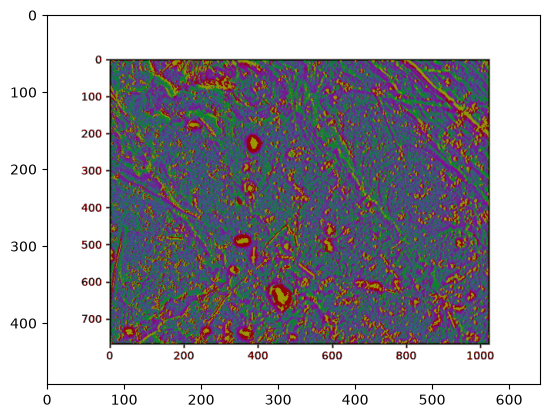

In [6]:
image4 = cv2.imread(Path("../notebooks/image4.png"), cv2.IMREAD_COLOR_RGB)

#Farbbild durch Histogramm-Equalisierung (Histogram Equalization) kontrastverstärkt
# rot, grün, blau = 0, 1, 2
hist_equalized_r = skimage.exposure.equalize_hist(image4[:,:,0])
hist_equalized_g = skimage.exposure.equalize_hist(image4[:,:,1])
hist_equalized_b = skimage.exposure.equalize_hist(image4[:,:,2])

hist_equalized = np.stack([hist_equalized_r, hist_equalized_g, hist_equalized_b], axis=-1)

plt.imshow(hist_equalized)
plt.show()

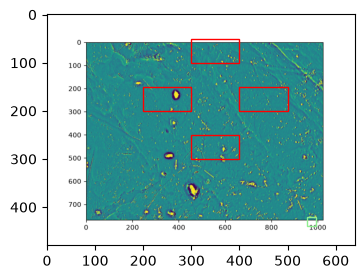

In [7]:
# Blob rectangles (areas of interest)
blob_rects = np.array([
    # left, right, bottom, top
    [400, 300, 50, 100],
    [500, 400, 150, 200],
    [300, 200, 150, 200],
    [400, 300, 300, 250],
])

# Background rectangles (non-blob areas)
bgd_rects = np.array([
    # left, right, bottom, top
    [1020, 1040, 255, 265],
    [540, 560, 420, 440],
])

#Matplotlib unterscheidet zwischen dem gesamten Bildfenster (fig) und dem Bereich, in dem tatsächlich gezeichnet wird (ax).
fig, ax = plt.subplots(1,1 , figsize=(4, 3))

ax.imshow(image4)

#Rechtecke erzeugen 
for blob in blob_rects:
    # 0= X, 2= Y, fc= Füllfarbe, ec= Linienfarbe
    rect = mpl.patches.Rectangle([blob[0], blob[2]], width=blob[1] - blob[0], height=blob[3] - blob[2], fc='none', ec='red')
    ax.add_patch(rect)
for blob in bgd_rects:
    rect = mpl.patches.Rectangle([blob[0], blob[2]], width=blob[1] - blob[0], height=blob[3] - blob[2], fc='none', ec='lightgreen')
    ax.add_patch(rect)
## Anzeigen eines Bildausschnitts
#ax.set(xlim=(500, 600), ylim=(400, 500))
plt.show()

400
500
300
400


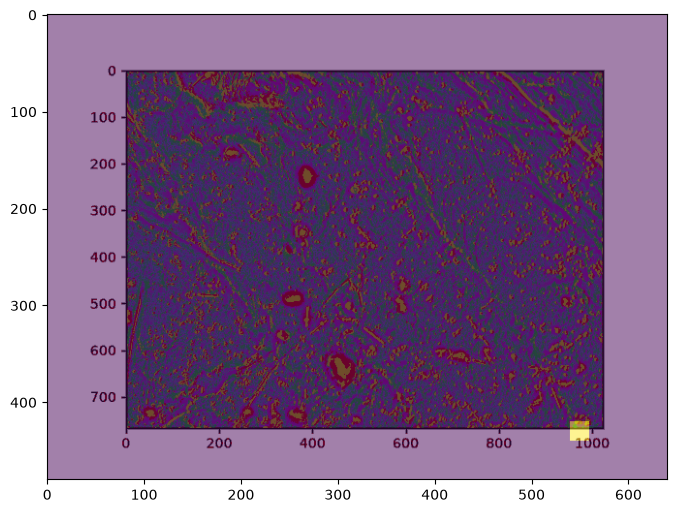

In [8]:
# hist_equalized.shape hat 3 Dimensionen (Höhe, Breite, Farbkanal), [:2] übernimmt nur die ersten beiden Dimensionen
label_map = np.zeros(hist_equalized.shape[:2])# * np.nan
# r0, r1, c0, c1 = Koordinaten der Rechtecke
for (r0, r1, c0, c1) in blob_rects:
    #alle Pixel innerhalb der Rechtecke bekommen den Wert 2 (Blob)
    label_map[c0:c1,r0:r1] = 2
    print(r0)

for (r0, r1, c0, c1) in bgd_rects:
    #alle Pixel innerhalb der Rechtecke bekommen den Wert 1 (Hintergrund)
    label_map[c0:c1,r0:r1] = 1

    #Falls sich Rechtecke überlappen, überschreibt die später ausgeführte Zuweisung die vorherige. 
    # Es haben also die Hintergrundbereiche Vorrang, wenn sie einen Blob-Bereich überdecken.

#lable Map wird über das kontrastverstärkte Bild gelegt, 1, 2 werden als unterschiedliche Farben dargestellt
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.imshow(hist_equalized)
ax.imshow(label_map, alpha=0.5) # alpha= Transparenz
plt.show()

In [9]:
print(f'Number of background pixels: {np.sum(label_map == 1)}')
print(f'Number of blob pixels:       {np.sum(label_map == 2)}')

Number of background pixels: 400
Number of blob pixels:       0


In [10]:
features = skimage.feature.multiscale_basic_features(image=image4,
                                                     intensity=True, edges=True, texture=False,
                                                     sigma_min=0.5, sigma_max=32, num_sigma=10,
                                                     channel_axis=2)
# Das Ergebnis features ist ein dreidimensionales NumPy-Array: Höhe. Breite, Anzahl der Features
print(features.shape)

(480, 640, 60)


In [11]:
# erstellt und trainiert einen Random-Forest-Klassifikator, der lernen soll, Blob-Pixel vom Hintergrund zu unterscheiden
# erstellt ein Modell aus 100 Entscheidungsbäumen
classifier = RandomForestClassifier(n_estimators=100, n_jobs=-1, max_features='sqrt', max_depth=5, max_samples=0.05, criterion='gini')
# trainiert das Modell anhand der berechneten Bildmerkmale (features) und der manuell beschrifteten Pixel (label_map)
classifier = skimage.future.fit_segmenter(label_map, features, classifier)

In [12]:
# der trainierte Random-Forest-Klassifikator wird auf das Bild angewendet,
# jeder Pixel erhält eine Vorhersage, ob er zu einem Blob (2) oder zum Hintergrund (1) gehört
prediction = skimage.future.predict_segmenter(features, classifier)

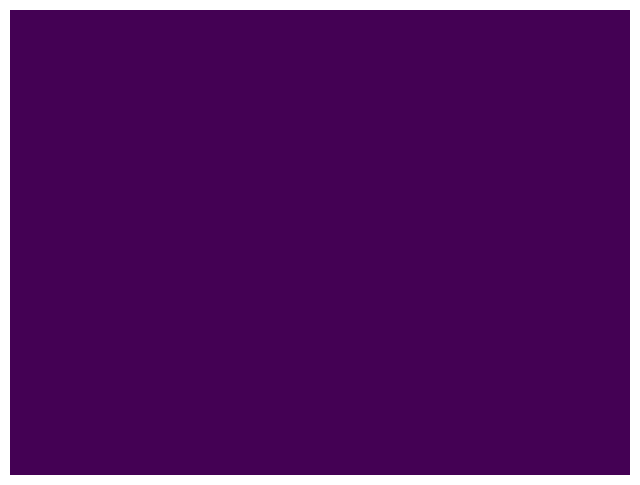

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.imshow(prediction)
ax.set_axis_off()
plt.show()

In [14]:
# binäre Maske umgewandelt, die nur noch die Blob-Pixel markiert
# für Blob wird der Wert 1 gesetzt, für Hintergrund der Wert 0
predicted_blobs = np.where(prediction == 2, 1, 0)

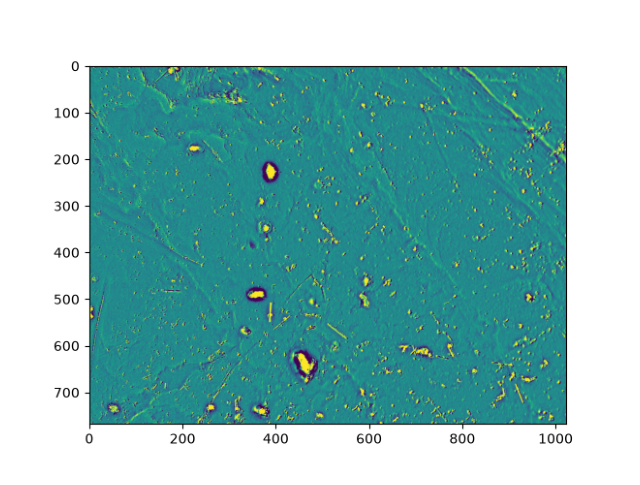

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.imshow(image4)
ax.contour(predicted_blobs, cmap='inferno')
ax.set_axis_off()
plt.show()

In [ ]:
image_grayscale = cv2.imread('./data/other/full_image.png', cv2.IMREAD_GRAYSCALE)
# approximate blob radius in pixels
r_min = 5
r_max = 10 
blobs = skimage.feature.blob_log(image_grayscale, min_sigma=r_min/np.sqrt(2), max_sigma=r_max/np.sqrt(2), num_sigma=50, threshold=1e-2)

ValueError: Cannot convert from object to float64.

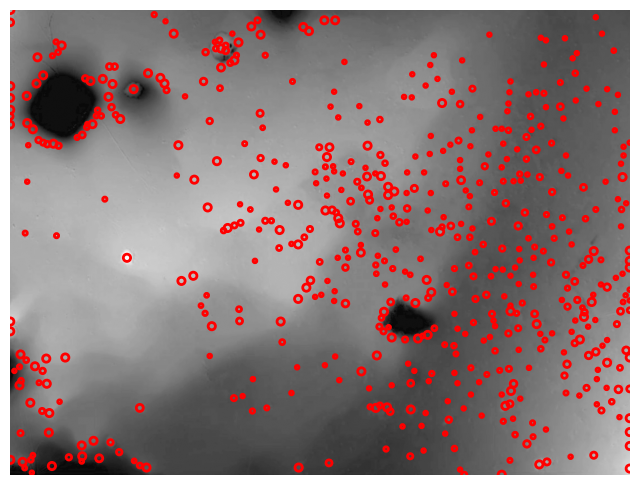

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.imshow(image_grayscale, cmap='gray')
for blob in blobs:
    y, x, r = blob
    c = plt.Circle((x, y), r, color='red', linewidth=2, fill=False)
    ax.add_patch(c)
ax.set_axis_off()
plt.show()